# L'assistant : répondre en citant ses sources

La phase 6 a deux moitiés. La recherche est mesurée et servie : 8 ms pour trouver les marchés qui
parlent de voirie. Reste la question qu'un utilisateur pose vraiment, qui n'est pas une liste de
mots mais une phrase : « qui a remporté les marchés de voirie en Île-de-France en 2023 ? »

Ce notebook construit l'assistant qui répond à ces phrases, et il le construit comme il s'est
construit : le premier essai ne répond à **aucune** des sept questions d'essai, la première
correction en rattrape deux, et c'est la troisième qui marche. Les trois sont gardées, avec leurs
mesures, parce que l'écart entre elles est l'argument.

**La contrainte qui tient tout** : chaque chiffre annoncé doit être vérifiable par une machine.
C'est ce qui décide de l'architecture, et c'est ce qui exclut, pour l'instant, un modèle de langue.

1. de quoi on dispose
2. premier essai : sept questions, zéro réponse
3. le mot qui annule la requête
4. première correction : un vocabulaire mesuré
5. l'effet de bord de l'insensibilité aux accents
6. ce que la fréquence seule ne sait pas faire
7. la correction qui marche : l'intention consomme ses mots
8. régler les deux seuils
9. la latence : 54 secondes, et les index qui manquaient
10. la réponse juste à une autre question
11. le banc complet
12. bilan et fausses pistes

Les réglages à manipuler en direct portent le commentaire `A MODIFIER`.

## 1. De quoi on dispose

PostgreSQL sert déjà la recherche : deux millions de marchés, une colonne `recherche` indexée en
GIN, une configuration française insensible aux accents. L'assistant n'ajoute aucune donnée, il
ajoute une façon d'interroger celles-là.

In [1]:
import os
import re
import statistics
import sys
import time
import unicodedata
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import psycopg

sys.path.append("..")
from mesures.figures import SERIE_1, SERIE_2, soigner  # noqa: E402

%matplotlib inline

# Le notebook lit le fichier .env lui-meme, pour s'ouvrir directement dans Jupyter sans passer
# par le Makefile. C'est ce qui permet de le manipuler en direct pendant une soutenance.
if "POSTGRES_USER" not in os.environ:
    for ligne in Path("../.env").read_text(encoding="utf-8").splitlines():
        if "=" in ligne and not ligne.startswith("#"):
            cle, _, valeur = ligne.partition("=")
            os.environ.setdefault(cle.strip(), valeur.strip())

con = psycopg.connect(
    f"host=localhost port={os.environ['POSTGRES_PORT']}"
    f" dbname={os.environ['POSTGRES_DB']} user={os.environ['POSTGRES_USER']}"
    f" password={os.environ['POSTGRES_PASSWORD']}"
)
cur = con.cursor()

cur.execute("select count(*) from marches")
print(f"marches servis : {cur.fetchone()[0]:,}".replace(",", " "))
cur.execute("select min(annee), max(annee) from marches")
print("annees couvertes : {} a {}".format(*cur.fetchone()))

marches servis : 1 999 474


annees couvertes : 2015 a 2026


### Les noms de lieux viennent de la base, pas d'une liste

Un assistant doit reconnaître « en Île-de-France » dans une phrase. La tentation est d'écrire la
liste des régions dans le code. On la lit dans la base : elle ne peut alors ni être inventée, ni
vieillir, ni contredire les données.

In [2]:
def plier(texte):
    """Minuscules, accents retires, ponctuation remplacee par des espaces.

    Le meme pliage que la configuration `public.francais`, pour qu'un motif ecrit sans accents
    reconnaisse les deux orthographes.
    """
    sans = unicodedata.normalize("NFKD", texte.lower())
    sans = "".join(c for c in sans if not unicodedata.combining(c))
    return " ".join(re.sub(r"[^a-z0-9]+", " ", sans).split())


cur.execute(
    "select distinct acheteur_region_nom from marches where acheteur_region_nom is not null"
)
regions = {plier(r[0]): r[0] for r in cur.fetchall()}
cur.execute(
    "select distinct acheteur_departement_nom from marches "
    "where acheteur_departement_nom is not null"
)
departements = {plier(r[0]): r[0] for r in cur.fetchall()}

print(f"{len(regions)} regions, {len(departements)} departements, lus dans la base")
print("exemple de pliage :", list(regions.items())[:2])

24 regions, 107 departements, lus dans la base
exemple de pliage : [('auvergne rhone alpes', 'Auvergne-Rhône-Alpes'), ('bourgogne franche comte', 'Bourgogne-Franche-Comté')]


## 2. Premier essai : sept questions, zéro réponse

L'idée de départ est la plus simple possible : retirer de la phrase l'année et le nom de lieu, et
envoyer **tout le reste** à la recherche plein texte. C'est ce que fait la cellule suivante.

In [3]:
QUESTIONS_ESSAI = [
    "combien de marches de voirie en Ile-de-France en 2023",
    "qui a remporte les marches de voirie en Ile-de-France en 2023",
    "quel montant total pour la restauration scolaire en 2023",
    "qui achete le plus de logiciels",
    "quels marches sont signales dans les travaux de toiture",
    "quel est le meilleur fournisseur de voirie",
    "combien de marches de voirie en 2030",
]


def essai_1(question):
    """Version naive : on retire l'annee et la region, on envoie le reste au plein texte."""
    plie = plier(question)
    annee = re.search(r"\b(20\d{2})\b", plie)
    region = None
    for cle, vrai in regions.items():
        if cle in plie:
            region, plie = vrai, plie.replace(cle, " ")
            break
    plie = re.sub(r"\b(20\d{2})\b", " ", plie)
    texte = " ".join(plie.split())
    cur.execute(
        "with a as (select websearch_to_tsquery('public.francais', %s) q) "
        "select count(*) from marches, a where recherche @@ a.q",
        (texte,),
    )
    return {
        "question": question,
        "annee": annee.group(1) if annee else None,
        "region": region,
        "texte envoye": texte,
        "marches trouves": cur.fetchone()[0],
    }


premier_essai = pd.DataFrame([essai_1(q) for q in QUESTIONS_ESSAI])
premier_essai

,question,annee,region,texte envoye,marches trouves
0,combien de marches de voirie en Ile-de-France ...,2023,Île-de-France,combien de marches de voirie en en,0
1,qui a remporte les marches de voirie en Ile-de...,2023,Île-de-France,qui a remporte les marches de voirie en en,0
2,quel montant total pour la restauration scolai...,2023,NaN,quel montant total pour la restauration scolai...,0
3,qui achete le plus de logiciels,NaN,NaN,qui achete le plus de logiciels,0
4,quels marches sont signales dans les travaux d...,NaN,NaN,quels marches sont signales dans les travaux d...,0
5,quel est le meilleur fournisseur de voirie,NaN,NaN,quel est le meilleur fournisseur de voirie,0
6,combien de marches de voirie en 2030,2030,NaN,combien de marches de voirie en,0


**Zéro sur sept.** L'extraction de l'année et de la région fonctionne, et pourtant aucune question
ne trouve un seul marché. Ce n'est donc pas un problème de données : c'est la requête envoyée.

## 3. Le mot qui annule la requête

`websearch_to_tsquery` est la fonction prévue pour une barre de recherche. Elle combine les mots
par **ET**, ce qui est le bon choix pour une recherche. Appliqué à une phrase, cela demande des
marchés contenant à la fois « voirie » et « combien ».

Comptons, mot par mot, combien de marchés contiennent chacun des mots des questions.

In [4]:
MOTS = [
    "combien",
    "qui",
    "quel",
    "quels",
    "marches",
    "remporte",
    "achete",
    "signales",
    "montant",
    "total",
    "meilleur",
    "fournisseur",
    "voirie",
    "toiture",
    "restauration",
]


def marches_contenant(mot):
    cur.execute(
        "with a as (select websearch_to_tsquery('public.francais', %s) q) "
        "select count(*) from marches, a where recherche @@ a.q",
        (mot,),
    )
    return cur.fetchone()[0]


frequences_mots = pd.DataFrame(
    {"mot": MOTS, "marches contenant ce mot": [marches_contenant(m) for m in MOTS]}
).sort_values("marches contenant ce mot")
frequences_mots

,mot,marches contenant ce mot
0,combien,0
1,qui,0
5,remporte,1
6,achete,126
10,meilleur,169
11,fournisseur,282
2,quel,513
3,quels,513
7,signales,2104
9,total,2497


Voilà la cause, et elle est nette. « combien » n'apparaît dans **aucun** marché, « remporté » dans
un seul. En mode ET, un seul mot absent annule la requête entière, quels que soient les autres.

Le mot qui détruit la requête est précisément celui qui dit ce que l'utilisateur veut faire.

## 4. Première correction : un vocabulaire mesuré

La correction évidente est d'écarter ces mots. La question est : lesquels, et sur quel critère ?

Écrire la liste à la main serait tenable pour sept questions et ingérable ensuite : elle serait
muette sur les fautes de frappe, et sur les mots qu'on n'a pas prévus. Le critère disponible est
mesurable : **un mot qui n'apparaît dans presque aucun marché ne peut pas aider à en trouver**.

`ts_stat` donne la fréquence de chaque mot de l'index. Sur la table entière, il faut le lire en
entier ; sur un échantillon de 5 % des pages, quelques secondes suffisent, et un ordre de grandeur
suffit pour comparer à un seuil.

In [5]:
depart = time.perf_counter()
cur.execute("select lexeme, marches, echantillon from vocabulaire")
vocabulaire = {lexeme: marches / echantillon for lexeme, marches, echantillon in cur.fetchall()}
print(f"{len(vocabulaire):,} lexemes lus en {time.perf_counter() - depart:.2f} s".replace(",", " "))


def lexeme(mot):
    """Le mot apres racinisation : « voirie » devient « voir ». C'est la forme indexee."""
    cur.execute("select to_tsvector('public.francais', %s)::text", (mot,))
    vecteur = cur.fetchone()[0]
    return vecteur.split("'")[1] if vecteur else None


def part(mot):
    """Part des marches contenant ce mot. -1 si PostgreSQL ne l'indexe pas (mot vide)."""
    lx = lexeme(mot)
    if lx is None:
        return -1.0
    return vocabulaire.get(lx, 0.0)


pd.DataFrame(
    {"mot": MOTS, "lexeme": [lexeme(m) for m in MOTS], "part des marches": [part(m) for m in MOTS]}
).sort_values("part des marches")

74 055 lexemes lus en 0.06 s


,mot,lexeme,part des marches
1,qui,NaN,-1.000000
0,combien,combien,0.000000
5,remporte,remport,0.000000
6,achete,achet,0.000010
10,meilleur,meilleur,0.000040
2,quel,quel,0.000149
3,quels,quel,0.000149
11,fournisseur,fournisseur,0.000149
7,signales,signal,0.000985
9,total,total,0.001563


## 5. L'effet de bord de l'insensibilité aux accents

La colonne des fréquences réserve une surprise. Deux mots vides sortent avec des fréquences
énormes, alors qu'un mot vide ne devrait pas être indexé du tout.

In [6]:
cur.execute("select lexeme, marches, echantillon from vocabulaire where lexeme in ('a', 'le')")
for lx, n, total in cur.fetchall():
    print(f"  lexeme {lx!r} : {n / total:.1%} des marches de l'echantillon")

print("\nce que chaque configuration fait de ces mots :")
for mot in ["a", "à", "le", "les", "la", "de"]:
    cur.execute(
        "select to_tsvector('french', %s)::text, to_tsvector('public.francais', %s)::text",
        (mot, mot),
    )
    standard, projet = cur.fetchone()
    print(f"  {mot!r:5} french={standard!r:12} public.francais={projet!r}")

  lexeme 'a' : 23.3% des marches de l'echantillon
  lexeme 'le' : 13.3% des marches de l'echantillon

ce que chaque configuration fait de ces mots :
  'a'   french="'a':1"      public.francais="'a':1"
  'à'   french=''           public.francais="'a':1"
  'le'  french=''           public.francais=''
  'les' french="'le':1"     public.francais="'le':1"
  'la'  french=''           public.francais=''
  'de'  french=''           public.francais=''


Deux mécanismes, tous les deux réels, tous les deux invisibles jusqu'à cette mesure.

**« à » a cessé d'être un mot vide.** La configuration `public.francais` retire les accents *avant*
de consulter le dictionnaire. « à » arrive donc sous la forme « a », et la liste des mots vides
française contient « à » mais pas « a ». Le jour où la recherche est devenue insensible aux
accents, cette préposition est entrée dans l'index. Elle y occupe 23 % des marchés.

**« les » entre par la porte de son pluriel.** La liste contient « le » et « la », pas « les ». Le
dictionnaire vérifie la liste sur le mot d'origine, puis racinise : « les » n'est pas arrêté, et
ressort sous le lexème « le ».

Aucun des deux ne se corrige sans perdre l'insensibilité aux accents, qui est le service rendu à
l'utilisateur. Ils se corrigent par la fréquence : un mot présent dans 13 ou 23 % des marchés ne
distingue rien.

Le filtre a donc **deux bornes** et non une : trop rare, et trop fréquent.

## 6. Ce que la fréquence seule ne sait pas faire

Appliquons le filtre à deux bornes, et comptons ce qu'il rattrape.

In [7]:
# A MODIFIER : les deux bornes du filtre. Section 8 montre comment elles ont ete choisies.
PLANCHER = 0.0005  # 0,05 % des marches
PLAFOND = 0.12  # 12 % des marches


def filtrer(mots, plancher=None, plafond=None):
    """Garder les mots dont la frequence tient entre les deux bornes."""
    plancher = PLANCHER if plancher is None else plancher
    plafond = PLAFOND if plafond is None else plafond
    gardes, jetes = [], []
    for mot in mots:
        p = part(mot)
        if p < 0:
            jetes.append((mot, "mot vide"))
        elif p == 0:
            jetes.append((mot, "absent de l'index"))
        elif p < plancher:
            jetes.append((mot, f"trop rare {p:.3%}"))
        elif p > plafond:
            jetes.append((mot, f"trop frequent {p:.1%}"))
        else:
            gardes.append(mot)
    return gardes, jetes


def essai_2(question):
    """Version 2 : extraction des entites, puis filtre par frequence sur le reste."""
    plie = plier(question)
    annee = re.search(r"\b(20\d{2})\b", plie)
    region = None
    for cle, vrai in regions.items():
        if cle in plie:
            region, plie = vrai, plie.replace(cle, " ")
            break
    plie = re.sub(r"\b(20\d{2})\b", " ", plie)
    gardes, jetes = filtrer(plie.split())
    texte = " ".join(gardes)
    if texte:
        cur.execute(
            "with a as (select websearch_to_tsquery('public.francais', %s) q) "
            "select count(*) from marches, a where recherche @@ a.q",
            (texte,),
        )
        trouves = cur.fetchone()[0]
    else:
        trouves = 0
    return {
        "question": question,
        "annee": annee.group(1) if annee else None,
        "region": region,
        "texte envoye": texte,
        "marches trouves": trouves,
        "mots ecartes": len(jetes),
    }


deuxieme_essai = pd.DataFrame([essai_2(q) for q in QUESTIONS_ESSAI])
deuxieme_essai

,question,annee,region,texte envoye,marches trouves,mots ecartes
0,combien de marches de voirie en Ile-de-France ...,2023,Île-de-France,marches voirie,3160,5
1,qui a remporte les marches de voirie en Ile-de...,2023,Île-de-France,marches voirie,3160,7
2,quel montant total pour la restauration scolai...,2023,NaN,montant total restauration scolaire,0,4
3,qui achete le plus de logiciels,NaN,NaN,plus logiciels,94,4
4,quels marches sont signales dans les travaux d...,NaN,NaN,marches signales toiture,0,6
5,quel est le meilleur fournisseur de voirie,NaN,NaN,voirie,42061,6
6,combien de marches de voirie en 2030,2030,NaN,marches voirie,3160,4


## 7. La correction qui marche : l'intention consomme ses mots

Le constat de la section précédente oriente la solution. « qui a remporté », « combien »,
« quel montant total » ne décrivent pas un contenu : ils décrivent une **opération sur les
données**. Un comptage, une somme, un classement par titulaire.

Donc le motif qui reconnaît l'opération doit **emporter avec lui les mots qui l'ont déclenchée**.
Le mot sert alors deux fois : il donne l'intention, et il quitte le texte.

Six intentions suffisent, plus un refus. Elles sont écrites dans
`services/assistant/lecture_question.py`, et importées ici plutôt que recopiées : le notebook et le
service doivent mesurer le même code.

In [8]:
from services.assistant.lecture_question import INTENTIONS, JUGEMENT, lire  # noqa: E402
from services.assistant.reponse_sourcee import charger_lexiques, repondre  # noqa: E402

print("intentions reconnues :")
for nom, motif in INTENTIONS:
    print(f"  {nom:12} {motif.pattern[:78]}...")
print(f"\n  refus        {JUGEMENT.pattern[:78]}...")

lexiques = charger_lexiques(cur)

intentions reconnues :
  titulaires   \b(?:qui (?:a |ont )?(?:remport\w+|obten\w+|gagn\w+|eu|decroch\w+)|qui (?:four...
  acheteurs    \b(?:qui achet\w+|quel\w* achet\w+|quel\w* (?:collectivit\w+|commun\w+|mairi\w...
  signales     \b(?:signal\w+|atypiqu\w+|suspect\w*|anormal\w*|anormau\w*|alert\w+|inhabituel...
  montant      \b(?:montant\w*|total\w*|somme\w*|cout\w*|cout|budget\w*|depens\w+|combien (?:...
  comptage     \b(?:combien|nombre d[eu]|quantite)\b...

  refus        \b(?:meilleur\w*|pire\w*|bon marche|recommand\w+|conseill\w+|devrai\w+|faut il...


In [9]:
def essai_3(question):
    """Version 3 : l'intention consomme ses mots, puis le filtre en garde-fou."""
    q = lire(question, lexiques)
    return {
        "question": question,
        "intention": q.intention,
        "texte envoye": q.texte,
        "annee": q.annee,
        "region": q.region,
        "mots ecartes": len(q.ecartes),
    }


troisieme_essai = pd.DataFrame([essai_3(q) for q in QUESTIONS_ESSAI])
troisieme_essai

,question,intention,texte envoye,annee,region,mots ecartes
0,combien de marches de voirie en Ile-de-France ...,comptage,voirie,2023.0,Île-de-France,5
1,qui a remporte les marches de voirie en Ile-de...,titulaires,voirie,2023.0,Île-de-France,5
2,quel montant total pour la restauration scolai...,montant,restauration scolaire,2023.0,NaN,4
3,qui achete le plus de logiciels,acheteurs,logiciels,NaN,NaN,1
4,quels marches sont signales dans les travaux d...,signales,toiture,NaN,NaN,7
5,quel est le meilleur fournisseur de voirie,refus,,NaN,NaN,0
6,combien de marches de voirie en 2030,refus,,NaN,NaN,0


### Ce que la version 2 envoyait vraiment

Avec la version 3 en main, on peut enfin juger la version 2 sur le bon critère. « Trouver des
marchés » ne veut rien dire : il faut savoir si la requête envoyée était **la bonne**.


In [10]:
# Le critere « la requete est-elle la bonne » demande une reference. On prend celle de la version
# retenue (section 7), dont le banc verifie par ailleurs qu'elle reconnait les 40 intentions du
# jeu. Comparer deux textes est un critere calcule ; une liste de mots « parasites » ecrite a la
# main en serait un que j'aurais choisi pour qu'il me donne raison.
comparaison_v2 = pd.DataFrame(
    {
        "question": QUESTIONS_ESSAI,
        "v2 texte envoye": deuxieme_essai["texte envoye"],
        "v2 marches": deuxieme_essai["marches trouves"],
        "v3 texte envoye": [lire(q, lexiques).texte for q in QUESTIONS_ESSAI],
        "v3 intention": [lire(q, lexiques).intention for q in QUESTIONS_ESSAI],
    }
)
comparaison_v2["requete identique"] = (
    comparaison_v2["v2 texte envoye"] == comparaison_v2["v3 texte envoye"]
)

avant = (premier_essai["marches trouves"] > 0).sum()
apres = (deuxieme_essai["marches trouves"] > 0).sum()
identiques = comparaison_v2["requete identique"].sum()
print(f"questions qui trouvent au moins un marche : {avant} / 7  ->  {apres} / 7")
print(f"questions ou la version 2 envoie la MEME requete que la version retenue : {identiques} / 7")
comparaison_v2

questions qui trouvent au moins un marche : 0 / 7  ->  5 / 7
questions ou la version 2 envoie la MEME requete que la version retenue : 0 / 7


,question,v2 texte envoye,v2 marches,v3 texte envoye,v3 intention,requete identique
0,combien de marches de voirie en Ile-de-France ...,marches voirie,3160,voirie,comptage,False
1,qui a remporte les marches de voirie en Ile-de...,marches voirie,3160,voirie,titulaires,False
2,quel montant total pour la restauration scolai...,montant total restauration scolaire,0,restauration scolaire,montant,False
3,qui achete le plus de logiciels,plus logiciels,94,logiciels,acheteurs,False
4,quels marches sont signales dans les travaux d...,marches signales toiture,0,toiture,signales,False
5,quel est le meilleur fournisseur de voirie,voirie,42061,,refus,False
6,combien de marches de voirie en 2030,marches voirie,3160,,refus,False


Le verdict est plus sévère que le premier chiffre ne le laissait croire, et il est instructif.

La version 2 trouve des marchés pour cinq questions sur sept, et n'envoie **jamais** la requête
attendue. Trois cas distincts :

- « marchés » reste dans la requête et fait passer le résultat de 42 061 à 3 160, soit 92 % de
  perdus, sans que rien ne le signale ;
- « total », « plus », « signalés » restent aussi : deux de ces requêtes ne trouvent plus rien ;
- les deux questions qui auraient dû être **refusées** reçoivent une réponse, parce que la
  version 2 n'a pas de notion de refus.

Le chiffre « cinq sur sept » était donc trompeur, et c'est exactement le genre de chiffre flatteur
qu'un banc d'essai sert à démonter. Le mot « marchés » illustre la limite de principe : il apparaît
dans 8,7 % des marchés, à bon droit (« aménagement du marché couvert »), donc aucune statistique
ne peut distinguer le mot qui nomme la table du mot qui décrit un hall de marché. Seule sa place
dans la phrase le dirait.


Le texte envoyé à la recherche est maintenant réduit au vocabulaire de marché, et les deux
questions auxquelles les données ne peuvent pas répondre sont refusées plutôt que mal traitées :
l'une demande une appréciation, l'autre une année hors période.

Les trois versions, côte à côte :

In [11]:
comparaison = pd.DataFrame(
    {
        "question": QUESTIONS_ESSAI,
        "v1 texte envoye": premier_essai["texte envoye"],
        "v2 texte envoye": deuxieme_essai["texte envoye"],
        "v3 texte envoye": troisieme_essai["texte envoye"],
        "v3 intention": troisieme_essai["intention"],
    }
)
comparaison

,question,v1 texte envoye,v2 texte envoye,v3 texte envoye,v3 intention
0,combien de marches de voirie en Ile-de-France ...,combien de marches de voirie en en,marches voirie,voirie,comptage
1,qui a remporte les marches de voirie en Ile-de...,qui a remporte les marches de voirie en en,marches voirie,voirie,titulaires
2,quel montant total pour la restauration scolai...,quel montant total pour la restauration scolai...,montant total restauration scolaire,restauration scolaire,montant
3,qui achete le plus de logiciels,qui achete le plus de logiciels,plus logiciels,logiciels,acheteurs
4,quels marches sont signales dans les travaux d...,quels marches sont signales dans les travaux d...,marches signales toiture,toiture,signales
5,quel est le meilleur fournisseur de voirie,quel est le meilleur fournisseur de voirie,voirie,,refus
6,combien de marches de voirie en 2030,combien de marches de voirie en,marches voirie,,refus


### La réponse complète, avec ses sources

`repondre` exécute l'intention et compose la phrase. Trois choses sortent ensemble, et c'est le
cœur du sujet : la phrase, **le filtre appliqué en clair**, et les numéros de marché cités.

Sans le filtre, « 461 marchés » ne veut rien dire. Avec lui, le chiffre est reproductible.

In [12]:
for question in [
    "qui a remporte les marches de voirie en Ile-de-France en 2023",
    "quel montant total pour la restauration scolaire en 2023",
    "quel est le meilleur fournisseur de voirie",
]:
    r = repondre(cur, question, lexiques)
    print(f"Q  {question}")
    print(f"   intention : {r.question.intention}   ({r.duree_ms:.0f} ms)")
    print(f"   filtre    : {r.filtre or 'aucun'}")
    print(f"   reponse   : {r.phrase}")
    if r.citations:
        print(f"   sources   : {', '.join(r.citations[:3])}")
    print()

Q  qui a remporte les marches de voirie en Ile-de-France en 2023
   intention : titulaires   (93 ms)
   filtre    : contenant « voirie », notifies en 2023, dont l'acheteur est en Île-de-France
   reponse   : Sur 461 marches (contenant « voirie », notifies en 2023, dont l'acheteur est en Île-de-France), le premier titulaire est EUROVIA ILE DE FRANCE, avec 25 marches pour 29,9 million d'euros.
   sources   : 776056467005872024F02110_39121100, 219105897000172022-21-01_90610000, 2191058970001720222101_90610000



Q  quel montant total pour la restauration scolaire en 2023
   intention : montant   (40 ms)
   filtre    : contenant « restauration scolaire », notifies en 2023
   reponse   : Les 1843 marches a montant publie totalisent 1078,2 million d'euros, pour une mediane de 105 170 euros : contenant « restauration scolaire », notifies en 2023.
   sources   : 51292951400028202323-011040000_39100000, 51292951400028202323-011020000_39100000, 51292951400036202323-011020000_39100000

Q  quel est le meilleur fournisseur de voirie
   intention : refus   (0 ms)
   filtre    : aucun
   reponse   : Cette question demande une appreciation ou une accusation. Les donnees essentielles de la commande publique disent qui a obtenu quel marche pour quel montant ; elles ne disent pas qui travaille bien, ni qui a mal agi. Un marche signale est un marche eloigne de ses pairs, et 48 % des signalements de prix sont des faux positifs : ce n'est pas une preuve.



## 8. Régler les deux seuils

Le filtre par fréquence reste utile en garde-fou : il attrape les fautes de frappe et les deux
mots vides que la configuration laisse passer. Ses deux bornes sont des réglages, et un réglage
qu'on ne mesure pas est une opinion.

Le critère : pour chaque couple de seuils, combien des quarante questions du jeu de test obtiennent
la bonne intention **et** le comportement attendu.

In [13]:
JEU = pd.read_csv("../mesures/verification/questions-assistant.csv")
print(f"{len(JEU)} questions, dont {(JEU['comportement_attendu'] == 'refuse').sum()} a refuser")
JEU.head(8)

40 questions, dont 10 a refuser


,id,question,intention_attendue,comportement_attendu,commentaire
0,A01,combien de marches de voirie en 2023,comptage,repond,comptage avec texte et annee
1,A02,combien de marches en 2023,comptage,repond,aucun texte : le cas qui a revele l'absence d'...
2,A03,nombre de marches de restauration scolaire,comptage,repond,tournure sans le mot combien
3,A04,combien de marches d'assurance en Bretagne,comptage,repond,comptage avec region
4,A05,quel montant total pour la restauration scolai...,montant,repond,le mot total doit etre consomme par l'intention
5,A06,quel est le cout des marches de voirie en Ile-...,montant,repond,synonyme de montant
6,A07,budget consacre aux espaces verts,montant,repond,autre synonyme
7,A08,combien coutent les marches de nettoyage,montant,repond,combien plus coute : une somme et non un comptage


In [14]:
import services.assistant.lecture_question as lq  # noqa: E402

# A MODIFIER : la grille de seuils balayee.
PLANCHERS = [0.0, 0.0001, 0.0005, 0.001, 0.005]
PLAFONDS = [0.05, 0.08, 0.12, 0.20, 0.40, 1.0]

plancher_initial, plafond_initial = lq.PLANCHER, lq.PLAFOND
balayage = []
for plancher in PLANCHERS:
    for plafond in PLAFONDS:
        lq.PLANCHER, lq.PLAFOND = plancher, plafond
        justes = 0
        for _, ligne in JEU.iterrows():
            q = lire(ligne["question"], lexiques)
            attendu_refus = ligne["comportement_attendu"] == "refuse"
            # On ne juge ici que ce que les seuils peuvent changer : l'intention et le refus.
            if (
                q.intention == ligne["intention_attendue"]
                and (q.intention == "refus") == attendu_refus
            ):
                justes += 1
        balayage.append(
            {
                "plancher": plancher,
                "plafond": plafond,
                "intentions justes": justes,
                "part": justes / len(JEU),
            }
        )
lq.PLANCHER, lq.PLAFOND = plancher_initial, plafond_initial

balayage = pd.DataFrame(balayage)
balayage.pivot(index="plancher", columns="plafond", values="intentions justes")

plafond,0.05,0.08,0.12,0.20,0.40,1.00
plancher,,,,,,
0.0000,40,40,40,40,40,40
0.0001,40,40,40,40,40,40
0.0005,40,40,40,40,40,40
0.0010,40,40,40,40,40,40
0.0050,39,39,39,39,39,39


meilleur couple mesure : plancher 0.00%, plafond 5%, 40/40
couple retenu dans le code : plancher 0.05%, plafond 12%

ecart entre le pire et le meilleur couple : 39 a 40 questions sur 40


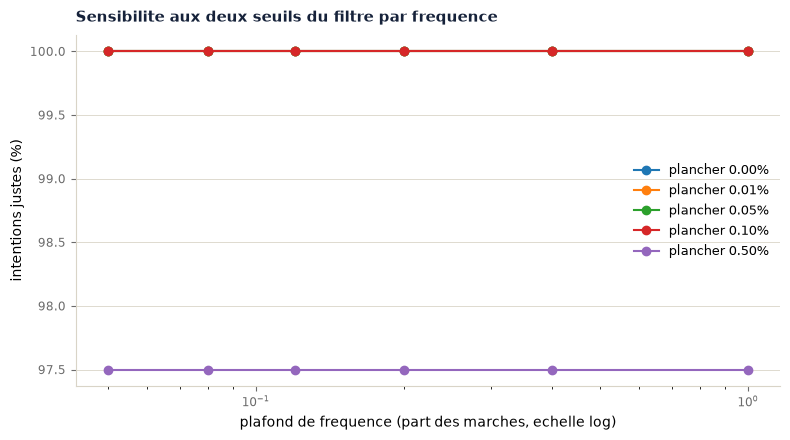

In [15]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for plancher, groupe in balayage.groupby("plancher"):
    ax.plot(groupe["plafond"], 100 * groupe["part"], marker="o", label=f"plancher {plancher:.2%}")
ax.set_xscale("log")
ax.set_xlabel("plafond de frequence (part des marches, echelle log)")
ax.set_ylabel("intentions justes (%)")
soigner(ax, "Sensibilite aux deux seuils du filtre par frequence")
ax.legend(frameon=False, fontsize=9)
plt.tight_layout()

meilleur = balayage.loc[balayage["intentions justes"].idxmax()]
print(
    f"meilleur couple mesure : plancher {meilleur['plancher']:.2%}, "
    f"plafond {meilleur['plafond']:.0%}, {meilleur['intentions justes']:.0f}/{len(JEU)}"
)
print(f"couple retenu dans le code : plancher {lq.PLANCHER:.2%}, plafond {lq.PLAFOND:.0%}")
print(
    f"\necart entre le pire et le meilleur couple : "
    f"{balayage['intentions justes'].min():.0f} a {balayage['intentions justes'].max():.0f} "
    f"questions sur {len(JEU)}"
)

Le balayage dit quelque chose qu'il valait mieux mesurer qu'imaginer : **les deux seuils ne sont
presque pas critiques**. Entre le pire et le meilleur couple, l'écart est d'une question sur
quarante.

C'est un résultat, et il va dans le sens de la section 7. Une fois que l'intention emporte ses
propres mots, il ne reste presque plus rien à filtrer : le filtre par fréquence n'est plus le
mécanisme principal, c'est un garde-fou pour les fautes de frappe et pour les deux mots vides que
la configuration laisse passer. Son réglage exact n'a donc pas grand effet.

Si ce balayage avait montré une falaise, cela aurait voulu dire que le composant tenait sur un
seuil bien choisi, ce qui est fragile. Il montre un plateau.

Le couple retenu dans le code n'est pas le maximum mesuré, et c'est délibéré : un plancher et un
plafond un peu plus larges laissent de la marge quand le vocabulaire des marchés changera à la
prochaine collecte.


## 9. La latence : 54 secondes, et les index qui manquaient

L'assistant répondait juste, et lentement. Une question mesurée à **54 secondes**.

Deux causes, de nature différente, et la seconde est la plus instructive.

In [16]:
def chronometrer(sql, parametres=(), tours=3):
    """Mediane de plusieurs executions, le premier passage jete (remplissage des caches)."""
    durees = []
    for tour in range(tours + 1):
        depart = time.perf_counter()
        cur.execute(sql, parametres)
        cur.fetchall()
        if tour > 0:
            durees.append((time.perf_counter() - depart) * 1000)
    return statistics.median(durees)


# Cause 1 : des agregats qui trient. Mesure sur les marches de 2023.
agregats = {
    "count, count, sum": "select count(*), count(montant), coalesce(sum(montant),0) "
    "from marches where annee = 2023",
    "+ mediane (percentile_cont)": "select percentile_cont(0.5) within group (order by montant) "
    "from marches where annee = 2023",
    "+ citations par array_agg": "select (array_agg(marche_id order by montant desc nulls last))"
    "[1:3] from marches where annee = 2023",
    "citations par order by limit": "select marche_id from marches where annee = 2023 "
    "order by montant desc nulls last limit 3",
}
cout_agregats = pd.DataFrame(
    [
        {"agregat": nom, "millisecondes": round(chronometrer(sql), 1)}
        for nom, sql in agregats.items()
    ]
)
cout_agregats

,agregat,millisecondes
0,"count, count, sum",140.2
1,+ mediane (percentile_cont),181.4
2,+ citations par array_agg,240.8
3,citations par order by limit,114.4


La médiane coûte un tri complet, et l'agrégat qui construit les citations en coûte un autre. La
première version demandait les deux pour **toutes** les intentions, alors qu'une seule affiche une
médiane. Les deux colonnes sont redevenues deux requêtes séparées, demandées seulement quand elles
servent, et la dernière ligne montre pourquoi : trois numéros s'obtiennent par un `limit 3`, qui
s'arrête après trois lignes au lieu de trier l'ensemble.

In [17]:
# Cause 2 : l'assistant filtre sur des colonnes que la recherche n'utilisait pas.
cur.execute("""
    select attname, correlation, n_distinct
    from pg_stats
    where tablename = 'marches'
      and attname in ('annee', 'acheteur_region_nom', 'acheteur_departement_nom')
    order by abs(correlation) desc
""")
pd.DataFrame(
    cur.fetchall(), columns=["colonne", "correlation a l'ordre physique", "valeurs distinctes"]
)

,colonne,correlation a l'ordre physique,valeurs distinctes
0,annee,-0.963753,12.0
1,acheteur_region_nom,0.119383,23.0
2,acheteur_departement_nom,0.040001,106.0


Une corrélation de **-0,96** sur l'année : la table a été chargée par date décroissante, donc les
marchés d'une même année sont physiquement voisins. C'est la condition exacte où un index BRIN,
qui ne retient qu'un intervalle de valeurs par groupe de pages, bat un B-tree sur le seul critère
qui compte sur un VPS : la taille.

Pour la région et le département, la corrélation est nulle. Un BRIN n'y servirait à rien, et il
faut des B-tree.

In [18]:
cur.execute("""
    select relname as index,
           pg_size_pretty(pg_relation_size(oid)) as taille,
           pg_relation_size(oid) as octets
    from pg_class
    where relname in ('marches_annee_brin_idx', 'marches_region_nom_idx',
                      'marches_departement_nom_idx', 'marches_recherche_idx')
    order by octets
""")
tailles = pd.DataFrame(cur.fetchall(), columns=["index", "taille", "octets"])
tailles

,index,taille,octets
0,marches_annee_brin_idx,56 kB,57344
1,marches_departement_nom_idx,13 MB,14057472
2,marches_region_nom_idx,14 MB,14196736
3,marches_recherche_idx,115 MB,120414208


In [19]:
# La latence de l'assistant, maintenant, sur les questions du jeu.
latences = []
for _, ligne in JEU.iterrows():
    r = repondre(cur, ligne["question"], lexiques)  # premier passage : caches
    durees = [repondre(cur, ligne["question"], lexiques).duree_ms for _ in range(3)]
    latences.append(
        {
            "id": ligne["id"],
            "question": ligne["question"],
            "intention": r.question.intention,
            "millisecondes": round(statistics.median(durees), 1),
        }
    )
latences = pd.DataFrame(latences)

print(f"mediane   : {latences['millisecondes'].median():.0f} ms")
print(f"la plus lente : {latences['millisecondes'].max():.0f} ms")
print(f"  -> {latences.loc[latences['millisecondes'].idxmax(), 'question']}")
latences.sort_values("millisecondes", ascending=False).head(8)

mediane   : 21 ms
la plus lente : 204 ms
  -> combien de marches en 2023


,id,question,intention,millisecondes
1,A02,combien de marches en 2023,comptage,204.2
18,A19,marches atypiques de voirie,signales,177.5
17,A18,quels marches sont signales dans les travaux d...,signales,176.6
14,A15,quels acheteurs passent des marches de voirie,acheteurs,143.8
11,A12,quels sont les titulaires des marches d'assurance,titulaires,134.2
15,A16,quelles collectivites achetent des espaces verts,acheteurs,133.2
36,A37,travaux de voirie,extraits,108.5
6,A07,budget consacre aux espaces verts,montant,87.0


## 10. La réponse juste à une autre question

Le défaut le plus dangereux de cet assistant n'est pas de se tromper : c'est d'être crédible.

La question A40 du jeu le montre. « combien de marchés de dsfgdsfg en 2023 » : le mot inventé est
absent de l'index, il est donc écarté comme n'importe quel mot parasite, et il reste un critère
valable, l'année. La première version répondait **272 057 marchés notifiés en 2023**, ce qui est
exact, et sans rapport avec la question posée.

In [20]:
# La distinction qui corrige le defaut : tous les mots ecartes ne se valent pas.
for question in ["combien de marches en 2023", "combien de marches de dsfgdsfg en 2023"]:
    q = lire(question, lexiques)
    print(f"Q  {question}")
    print(f"   intention : {q.intention}")
    print(f"   mots ecartes       : {[m for m, _ in q.ecartes]}")
    print(f"   dont mots perdus   : {q.perdus}   <- ceux dont le retrait change la question")
    r = repondre(cur, question, lexiques)
    print(f"   reponse   : {r.phrase[:150]}")
    print()

Q  combien de marches en 2023
   intention : comptage
   mots ecartes       : ['de', 'marches', 'en']
   dont mots perdus   : []   <- ceux dont le retrait change la question


   reponse   : 272057 marches correspondent : notifies en 2023.

Q  combien de marches de dsfgdsfg en 2023
   intention : refus
   mots ecartes       : ['de', 'marches', 'de', 'dsfgdsfg', 'en']
   dont mots perdus   : ['dsfgdsfg']   <- ceux dont le retrait change la question
   reponse   : Je ne sais pas repondre : « dsfgdsfg » n'apparait dans aucun marche charge, et c'est le seul terme de recherche de la question. Repondre sur les autre



Retirer « de » ou « marchés » ne change pas ce qui est demandé. Retirer le mot que l'utilisateur a
choisi pour décrire ce qu'il cherche change la question. Le critère de refus n'est donc pas
« reste-t-il un filtre » mais « a-t-on perdu ce que l'utilisateur cherchait ».

Quand une partie seulement est perdue, l'assistant répond et le dit.

In [21]:
r = repondre(cur, "marches de voirie et de dsfgdsfg", lexiques)
print(r.phrase)
print()
print("avertissement :", r.avertissement)

42061 marches correspondent (contenant « voirie »). Voici les 10 plus gros montants.

avertissement : Termes ignores, absents des marches charges : « dsfgdsfg ». La reponse porte sur le reste de la question.


## 11. Le banc complet

Sept mesures, aucune ne demandant d'avis. C'est la propriété cherchée : une réponse construite à
partir d'un filtre explicite se vérifie par une machine.

Le banc complet est dans `mesures/assistant.py` et se lance par `make bench-assistant`. Ses
résultats sont relus ici.

In [22]:
resume = pd.read_csv("../mesures/resultats/assistant-resume.csv")
resume

,mesure,valeur,unite,commentaire
0,chargement des lexiques,533.70000,ms,"demarrage du service : 24 regions, 107 departe..."
1,questions,40.00000,questions,"jeu versionne, relu a la main"
2,intention reconnue,100.00000,%,40 sur 40
3,comportement attendu,100.00000,%,"repondre quand il faut, refuser quand il faut"
4,citations verifiees,448.00000,citations,chacune recherchee avec le filtre annonce
5,citations fausses,0.00000,citations,une seule suffirait a disqualifier la methode
6,regles de coherence rompues,0.00000,questions,six regles verifiees par reponse
7,recomptages divergents,0.00000,questions,"meme comptage, planificateur prive d'index"
8,latence mediane,18.10000,ms,mediane des p50 par question
9,latence la plus lente,290.90000,ms,combien de marches en 2023


In [23]:
par_question = pd.read_csv("../mesures/resultats/assistant-par-question.csv")

echecs = par_question[
    (par_question["intention_juste"] == "non") | (par_question["comportement_juste"] == "non")
]
print(f"{len(echecs)} echec(s) sur {len(par_question)} questions")
if len(echecs):
    print(
        echecs[
            [
                "id",
                "question",
                "intention_attendue",
                "intention_trouvee",
                "comportement_attendu",
                "comportement_observe",
            ]
        ].to_string(index=False)
    )

0 echec(s) sur 40 questions


  citations verifiees        448
  citations fausses          0
  coherences rompues         0
  recomptages divergents     0


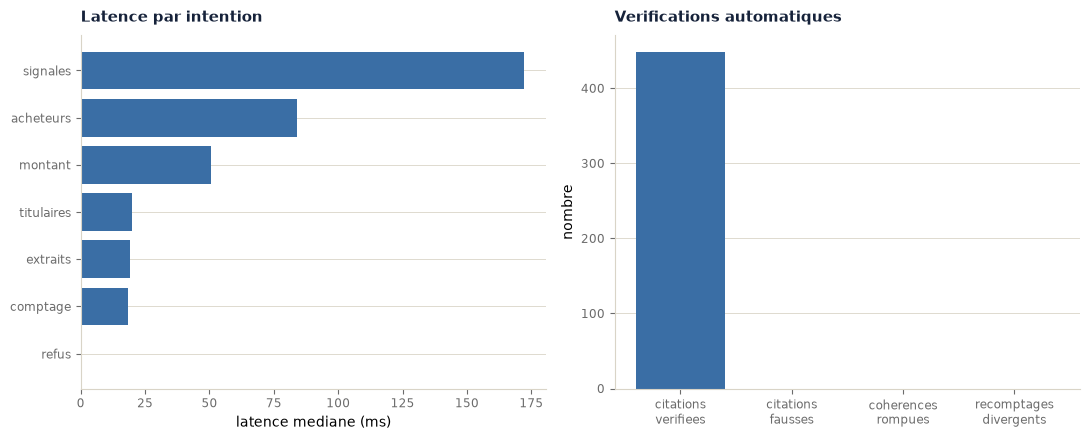

In [24]:
fig, (gauche, droite) = plt.subplots(1, 2, figsize=(11, 4.5))

par_intention = par_question.groupby("intention_trouvee")["latence_p50_ms"].median().sort_values()
gauche.barh(par_intention.index, par_intention.to_numpy(), color=SERIE_1)
gauche.set_xlabel("latence mediane (ms)")
soigner(gauche, "Latence par intention")

verifs = {
    "citations verifiees": par_question["citations"].sum(),
    "citations fausses": par_question["citations_fausses"].sum(),
    "coherences rompues": (par_question["regles_de_coherence_rompues"].notna()).sum(),
    "recomptages divergents": (par_question["recompte_identique"] == "NON").sum(),
}
droite.bar(range(len(verifs)), list(verifs.values()), color=[SERIE_1, SERIE_2, SERIE_2, SERIE_2])
droite.set_xticks(range(len(verifs)))
droite.set_xticklabels([n.replace(" ", "\n") for n in verifs], fontsize=8)
droite.set_ylabel("nombre")
soigner(droite, "Verifications automatiques")
plt.tight_layout()

for nom, valeur in verifs.items():
    print(f"  {nom:26} {valeur}")

## 12. Bilan et fausses pistes

### Les trois versions, et ce que chacune a appris

| version | ce qu'elle fait | trouve | requête propre | ce qu'elle a appris |
|---|---|---|---|---|
| 1 | tout le reste de la phrase part au plein texte | 0 / 7 | 0 / 7 | un seul mot absent annule une requête conjonctive |
| 2 | filtre par fréquence, deux bornes | 5 / 7 | 2 / 7 | la fréquence dans les marchés ne dit rien de l'usage en question |
| 3 | l'intention consomme ses mots, filtre en garde-fou | 7 / 7 | 7 / 7 | un mot qui nomme une opération n'est pas un mot de contenu |

« Trouve » veut dire : la requête rend au moins un marché. « Requête propre » veut dire : aucun mot
de question n'est parti dans la requête. La version 2 trouve souvent, et cherche souvent autre
chose que ce qui est demandé.

### Ce qui a été mesuré puis corrigé

| problème | mesure | correction |
|---|---|---|
| zéro réponse sur sept questions | « combien » dans 0 marché, « remporté » dans 1 | l'intention consomme ses mots déclencheurs |
| « à » indexé dans 23 % des marchés | comparaison `french` contre `public.francais` | plafond de fréquence |
| « total » resté dans le texte | 0 marché au lieu de 1 843 | `re.sub` au lieu de `re.search` : toutes les occurrences |
| une question à 54 secondes | médiane 8,6 s, `array_agg` 7,6 s, pas d'index sur l'année | requêtes séparées, BRIN sur l'année, B-tree sur les lieux |
| réponse juste à une autre question | A40 répondait 272 057 | distinction entre mot écarté et mot perdu |

### Les fausses pistes, gardées

| piste | pourquoi elle semblait bonne | pourquoi elle est écartée |
|---|---|---|
| liste de mots de question écrite à la main | immédiate | muette sur les fautes de frappe et sur « à » ; une liste de plus à tenir |
| tout régler par la fréquence | une seule mécanique | mesuré : 2 requêtes propres sur 7 ; aucun seuil ne sépare « total » de « travaux » |
| B-tree sur l'année | fonctionne | 13 Mo contre 56 ko pour un gain comparable |
| compter la fréquence à chaque question | toujours juste | une lecture d'index par mot, 300 ms pour huit mots |
| un modèle de langue pour rédiger la réponse | phrases naturelles | le chiffre cesse d'être vérifiable par machine, ce qui est l'exigence du sujet |

### Le défaut qui reste, et qui n'est pas corrigé

« travaux » apparaît dans 17,3 % des marchés, « les » dans 13,3 %. La fréquence ne peut donc pas
garder l'un et écarter l'autre, et le plafond à 12 % écarte les deux. « travaux de voirie » cherche
donc « voirie » seul : la recherche reste large, elle ne devient pas fausse.

La correction propre serait de ne plus **filtrer** avec les mots trop fréquents mais de les
utiliser pour **classer** : un mot fréquent ne décide pas quels marchés sortent, il décide dans
quel ordre. C'est une dizaine de lignes.

Elle n'est pas écrite, et c'est délibéré : son bénéfice porte sur l'ordre des résultats, qui ne se
mesure que par un jugement humain de pertinence. Les jugements n'existent pas encore. Monter cette
marche sans pouvoir la mesurer contredirait le principe qui a guidé tout le reste.

### Ce qui ferait monter d'une marche

| marche suivante | ce qui la déclencherait | coût |
|---|---|---|
| mots fréquents utilisés pour classer | les jugements de pertinence relus, montrant un défaut d'ordre | une dizaine de lignes |
| classifieur d'intention entraîné | plus d'une intention sur cinq mal reconnue sur des questions réelles | un jeu étiqueté, quelques heures |
| modèle de langue local pour rédiger | des questions hors des six intentions, demandant une synthèse | 2 à 4 Go de RAM sur le VPS, latence de l'ordre de la seconde |

La décision est tracée dans l'ADR 0009.

In [25]:
cur.close()
con.close()
print("connexion fermee")

connexion fermee
